<a href="https://colab.research.google.com/github/thealepo/cap5771-project/blob/main/experiments/RQ2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RQ2 - Discretization

In [1]:
# Colab only: uncomment these two lines to download the repo and move into it.
# Leave them commented out when running locally from the repo.
# !git clone https://github.com/thealepo/cap5771-project.git
# %cd cap5771-project

Cloning into 'cap5771-project'...
remote: Enumerating objects: 65, done.
remote: Counting objects: 100% (65/65), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 65 (delta 24), reused 53 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (65/65), 1.66 MiB | 4.81 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/cap5771-project


In [2]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == 'experiments':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from src.preprocessing import categoric_cols, numeric_cols, split_data
from src.discretization import continuous_cols, discretize_data

In [5]:
clean_path = ROOT / 'data' / 'preprocessed' / 'adult_cleaned.csv'
clean = pd.read_csv(clean_path)

# Same stratified 85/15 split as Part I and RQ1
train, test = split_data(clean)

print('Cleaned data:', clean.shape)
print('Training data:', train.shape)
print('Test data:', test.shape)

Cleaned data: (30096, 15)
Training data: (25581, 15)
Test data: (4515, 15)


## Settings

In [6]:
BIN_COUNTS = [3, 5, 8]
RANDOM_STATE = 42

# Dataset labels from the project instructions
METHOD_CODES = {
    'equal_width': 'd1',
    'equal_depth': 'd2',
    'kmeans': 'd3',
}

categorical_features = [col for col in categoric_cols if col != 'income']

print('Discretized features:', continuous_cols)
print('Numeric features left as they are:',
      [col for col in numeric_cols if col not in continuous_cols])

Discretized features: ['age', 'fnlwgt', 'capital_gain', 'capital_loss', 'hours_per_week']
Numeric features left as they are: ['education_num']


## Build the 10 dataset versions

In [7]:
versions = {}    # dataset name -> (train, test)
bin_edges = {}   # (method, n_bins) -> {feature: cut points}

# (d0) Original continuous attributes
versions['d0_original'] = (train, test)

# (d1)-(d3) with 3, 5 and 8 bins. Cut points are learned on train only.
for n_bins in BIN_COUNTS:
    binned_train, binned_test, all_edges = discretize_data(train, test, n_bins=n_bins)

    for method, method_code in METHOD_CODES.items():
        name = f'{method_code}_{method}_{n_bins}bins'
        versions[name] = (binned_train[method], binned_test[method])
        bin_edges[(method, n_bins)] = all_edges[method]

# Order: d0, then each method with 3, 5, 8 bins
version_order = ['d0_original'] + [
    f'{method_code}_{method}_{n_bins}bins'
    for method, method_code in METHOD_CODES.items()
    for n_bins in BIN_COUNTS
]

print(len(version_order), 'dataset versions:')
for name in version_order:
    print(' ', name)

10 dataset versions:
  d0_original
  d1_equal_width_3bins
  d1_equal_width_5bins
  d1_equal_width_8bins
  d2_equal_depth_3bins
  d2_equal_depth_5bins
  d2_equal_depth_8bins
  d3_kmeans_3bins
  d3_kmeans_5bins
  d3_kmeans_8bins


## (a) Bin ranges for each discretization method

In [8]:
def format_value(value):
    return f'{value:,.1f}'.rstrip('0').rstrip('.')


def edges_to_ranges(edges, low, high):
    """Turn cut points into readable ranges, e.g. [17, 31] | (31, 44] | (44, 90]."""
    points = [low] + list(edges) + [high]
    ranges = []

    for i in range(len(points) - 1):
        left_bracket = '[' if i == 0 else '('
        ranges.append(f'{left_bracket}{format_value(points[i])}, {format_value(points[i + 1])}]')

    return ranges


range_rows = []

for (method, n_bins), edges_by_feature in bin_edges.items():
    for feature in continuous_cols:
        edges = edges_by_feature[feature]
        ranges = edges_to_ranges(edges, train[feature].min(), train[feature].max())

        range_rows.append({
            'dataset': f'{METHOD_CODES[method]}_{method}',
            'bins_requested': n_bins,
            'bins_produced': len(ranges),
            'feature': feature,
            'bin_ranges': ' | '.join(ranges),
        })

bin_ranges = (
    pd.DataFrame(range_rows)
    .sort_values(['dataset', 'bins_requested'], kind='stable')
    .reset_index(drop=True)
)

with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(bin_ranges.style.set_caption(
        'Bin ranges learned on the training data for each discretization method'
    ))

collapsed = bin_ranges[bin_ranges['bins_produced'] < bin_ranges['bins_requested']]
print(f'{len(collapsed)} feature/method/bin-count combinations produced fewer bins than requested:')
display(collapsed[['dataset', 'bins_requested', 'bins_produced', 'feature']])

,dataset,bins_requested,bins_produced,feature,bin_ranges
0,d1_equal_width,3,3,age,"[17, 41.3] | (41.3, 65.7] | (65.7, 90]"
1,d1_equal_width,3,3,fnlwgt,"[13,769, 504,081] | (504,081, 994,393] | (994,393, 1,484,705]"
2,d1_equal_width,3,3,capital_gain,"[0, 33,333] | (33,333, 66,666] | (66,666, 99,999]"
3,d1_equal_width,3,3,capital_loss,"[0, 1,452] | (1,452, 2,904] | (2,904, 4,356]"
4,d1_equal_width,3,3,hours_per_week,"[1, 33.7] | (33.7, 66.3] | (66.3, 99]"
5,d1_equal_width,5,5,age,"[17, 31.6] | (31.6, 46.2] | (46.2, 60.8] | (60.8, 75.4] | (75.4, 90]"
6,d1_equal_width,5,5,fnlwgt,"[13,769, 307,956.2] | (307,956.2, 602,143.4] | (602,143.4, 896,330.6] | (896,330.6, 1,190,517.8] | (1,190,517.8, 1,484,705]"
7,d1_equal_width,5,5,capital_gain,"[0, 19,999.8] | (19,999.8, 39,999.6] | (39,999.6, 59,999.4] | (59,999.4, 79,999.2] | (79,999.2, 99,999]"
8,d1_equal_width,5,5,capital_loss,"[0, 871.2] | (871.2, 1,742.4] | (1,742.4, 2,613.6] | (2,613.6, 3,484.8] | (3,484.8, 4,356]"
9,d1_equal_width,5,5,hours_per_week,"[1, 20.6] | (20.6, 40.2] | (40.2, 59.8] | (59.8, 79.4] | (79.4, 99]"


9 feature/method/bin-count combinations produced fewer bins than requested:


,dataset,bins_requested,bins_produced,feature
17,d2_equal_depth,3,2,capital_gain
18,d2_equal_depth,3,2,capital_loss
19,d2_equal_depth,3,2,hours_per_week
22,d2_equal_depth,5,2,capital_gain
23,d2_equal_depth,5,2,capital_loss
24,d2_equal_depth,5,4,hours_per_week
27,d2_equal_depth,8,2,capital_gain
28,d2_equal_depth,8,2,capital_loss
29,d2_equal_depth,8,5,hours_per_week


## Train default DT and k-NN on every version

In [9]:
def prepare_features(train_df, test_df, classifier_name):
    """One-hot encode categorical features; scale numeric features for k-NN only.

    Same encoding/scaling as RQ1. For the discretized versions, the bin numbers
    (0, 1, 2, ...) are treated as ordered numbers, so k-NN scales them too.
    """
    numeric_step = StandardScaler() if classifier_name == 'kNN' else 'passthrough'

    transformer = ColumnTransformer([
        ('numeric', numeric_step, numeric_cols),
        ('categorical',
         OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         categorical_features),
    ])

    # Fit on train only, then apply to test
    X_train = transformer.fit_transform(train_df.drop(columns='income'))
    X_test = transformer.transform(test_df.drop(columns='income'))

    return X_train, X_test


def model_f1(model, features, target):
    return f1_score(target, model.predict(features), pos_label='>50K', zero_division=0)


# Default settings, as the instructions ask (random_state only fixes DT tie-breaking)
classifiers = {
    'DT': lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    'kNN': lambda: KNeighborsClassifier(),
}

rows = []

for name in version_order:
    train_df, test_df = versions[name]
    row = {'dataset': name}

    for classifier_name, make_model in classifiers.items():
        X_train, X_test = prepare_features(train_df, test_df, classifier_name)

        model = make_model()
        model.fit(X_train, train_df['income'])

        row[f'{classifier_name}_train_F1'] = model_f1(model, X_train, train_df['income'])
        row[f'{classifier_name}_test_F1'] = model_f1(model, X_test, test_df['income'])

    rows.append(row)
    print('Done:', name)

results = pd.DataFrame(rows).set_index('dataset')

Done: d0_original
Done: d1_equal_width_3bins
Done: d1_equal_width_5bins
Done: d1_equal_width_8bins
Done: d2_equal_depth_3bins
Done: d2_equal_depth_5bins
Done: d2_equal_depth_8bins
Done: d3_kmeans_3bins
Done: d3_kmeans_5bins
Done: d3_kmeans_8bins


## (b) Performance table

In [10]:
f1_columns = ['DT_train_F1', 'DT_test_F1', 'kNN_train_F1', 'kNN_test_F1']


def bold_best_underline_second(column):
    """Bold the best value in each column and underline the second best."""
    ranks = column.rank(method='min', ascending=False)
    return [
        'font-weight: bold' if rank == 1
        else 'text-decoration: underline' if rank == 2
        else ''
        for rank in ranks
    ]


styled_results = (
    results[f1_columns].style
    .format('{:.4f}')
    .apply(bold_best_underline_second)
    .set_caption('Train/test F1-score (positive class: >50K) of default DT and k-NN '
                 'on the 10 dataset versions (bold = best, underline = second best)')
)
display(styled_results)

,DT_train_F1,DT_test_F1,kNN_train_F1,kNN_test_F1
dataset,,,,
d0_original,0.9999,0.6334,0.7436,0.6519
d1_equal_width_3bins,0.7598,0.6085,0.6752,0.6201
d1_equal_width_5bins,0.8262,0.5904,0.7026,0.6229
d1_equal_width_8bins,0.8586,0.5738,0.7197,0.6327
d2_equal_depth_3bins,0.8448,0.5838,0.7202,0.6440
d2_equal_depth_5bins,0.9108,0.5888,0.7341,0.6323
d2_equal_depth_8bins,0.9482,0.5667,0.7424,0.6428
d3_kmeans_3bins,0.8380,0.6254,0.7219,0.6566
d3_kmeans_5bins,0.8708,0.6187,0.7336,0.6602


## Test F1 vs. number of bins

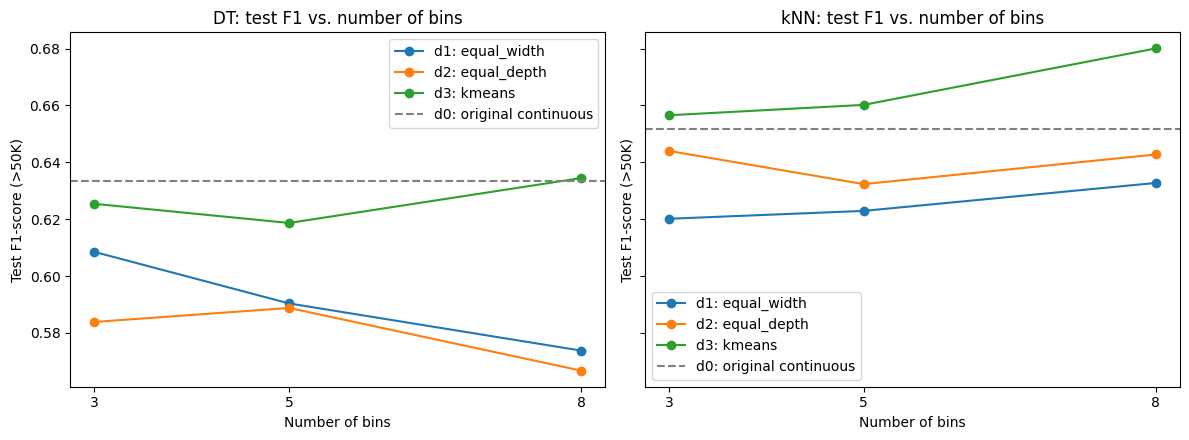

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, classifier_name in zip(axes, classifiers):
    column = f'{classifier_name}_test_F1'

    for method, method_code in METHOD_CODES.items():
        scores = [results.loc[f'{method_code}_{method}_{n}bins', column] for n in BIN_COUNTS]
        ax.plot(BIN_COUNTS, scores, marker='o', label=f'{method_code}: {method}')

    ax.axhline(results.loc['d0_original', column], color='gray', linestyle='--',
               label='d0: original continuous')

    ax.set_title(f'{classifier_name}: test F1 vs. number of bins')
    ax.set_xlabel('Number of bins')
    ax.set_xticks(BIN_COUNTS)
    ax.set_ylabel('Test F1-score (>50K)')
    ax.legend()

plt.tight_layout()

figure_directory = ROOT / 'results' / 'figures' / 'RQ2'
figure_directory.mkdir(parents=True, exist_ok=True)
plt.savefig(figure_directory / 'rq2_test_f1_vs_bins.png', dpi=150, bbox_inches='tight')
plt.show()

## Save result tables

In [12]:
output_directory = ROOT / 'results' / 'tables' / 'RQ2'
output_directory.mkdir(parents=True, exist_ok=True)

results.to_csv(output_directory / 'rq2_f1_scores.csv')
bin_ranges.to_csv(output_directory / 'rq2_bin_ranges.csv', index=False)

print('Saved:', output_directory / 'rq2_f1_scores.csv')
print('Saved:', output_directory / 'rq2_bin_ranges.csv')

Saved: /content/cap5771-project/results/tables/RQ2/rq2_f1_scores.csv
Saved: /content/cap5771-project/results/tables/RQ2/rq2_bin_ranges.csv
